# 04 · K-Means Customer Segmentation & Machine-Learning Clustering
**Customer Revenue Intelligence**, Step 6

> ⚠️ **SYNTHETIC DATA.** Input: `data/processed/customer_rfm_segments.csv`, the validated Step 5 customer table. Customers are identified by `Customer_ID` only.

This notebook presents the pipeline implemented in `src/segmentation.py`. **K-Means is unsupervised learning.** There is no target variable: the algorithm groups customers who are close together in a transformed feature space. Every number in the text also appears in the code output directly above it.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
from IPython.display import Image, display
import config
from src import segmentation as sg

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
FIG = config.FIGURES_DIR

# Full pipeline: features -> log1p -> scaling -> K evaluation -> K-Means -> profiling -> PCA -> comparison -> save
R = sg.run_segmentation(make_plots=True, verbose=False)
seg = R["segments"]
print(f"Customers clustered: {len(seg):,} | selected K = {R['k']} | files saved: {len(R['saved'])} | figures: {len(R['figures'])}")

Customers clustered: 1,984 | selected K = 4 | files saved: 25 | figures: 13


## 1. Segmentation Objective
The goal is to find **naturally occurring customer groups** from behaviour, and to answer these questions:
- How many clusters are there?
- What defines each one?
- Which clusters are high-value, frequent or recent, and which need retention attention?
- How do the ML clusters compare with the rule-based RFM segments from Step 5?

**Two separate methods:**
- **Step 5 (RFM):** humans wrote rules on quintile scores.
- **Step 6 (K-Means):** the algorithm forms the groups, and business labels are attached only *after* profiling.

## 2. Dataset Preparation

In [2]:
df = R["input"]
print(df.shape, "| unique customers:", df["Customer_ID"].nunique())
df[["Customer_ID", "Recency", "Frequency", "Monetary", "Average_Order_Value", "Total_Quantity", "Average_Discount", "RFM_Segment"]].head()

(1984, 29) | unique customers: 1984


,Customer_ID,Recency,Frequency,Monetary,Average_Order_Value,Total_Quantity,Average_Discount,RFM_Segment
0,CUST-0001,10,5,"10,990.150","2,198.030",7,0.092,Potential Loyalists
1,CUST-0002,2,11,"43,213.650","3,928.510",27,0.108,Champions
2,CUST-0003,146,6,"22,484.850","3,747.480",12,0.156,Loyal Customers
3,CUST-0004,90,3,"36,127.400","12,042.470",3,0.133,Needs Attention
4,CUST-0005,62,11,"38,964.450","3,542.220",19,0.108,Champions


**Population.** All **1,984 customers** scored in Step 5, with exactly one row each. The 16 customers with no delivered purchase were already excluded in Step 5, because they have no valid Recency or Monetary value. No further customers are removed here.

## 3. Feature Selection

In [3]:
R['feature_selection']['feature_decisions']

,Feature,Skewness,Max_abs_Spearman_with_core_RFM,Most_correlated_core_feature,Decision,Reason
0,Recency,2.050,0.380,Frequency,Include,Core RFM: how recently the customer bought (activity / churn signal)
1,Frequency,1.900,0.840,Monetary,Include,Core RFM: how often the customer buys (loyalty)
2,Monetary,3.210,0.840,Frequency,Include,Core RFM: how much the customer spends (value)
3,Average_Order_Value,6.700,0.810,Monetary,"Exclude from model, keep for profiling","= Monetary / Frequency, so it is a function of two included features; adding it lowered separation (see feature-set comparison)"
4,Total_Quantity,2.350,0.940,Frequency,Exclude,Near-duplicate of Frequency (Spearman rho shown) - would double-weight frequency
5,Average_Discount,0.620,0.300,Monetary,"Exclude from model, keep for profiling","Weakly related to RFM, but adding it lowered separation at every K compared (3-5); used to describe clusters instead"
6,Categories_Bought,0.040,0.860,Frequency,Exclude,Near-duplicate of Frequency (buying more often = more categories)
7,Tenure_Days,-0.670,0.430,Frequency,Exclude,"Measured from Jan 2023 for customers who existed earlier (truncated), so not a true tenure"


In [4]:
R['feature_selection']['feature_set_comparison']

,Feature_Set,k,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,"A: R, F, M (selected)",3,0.327,1.064,"1,434.000"
1,"A: R, F, M (selected)",4,0.353,0.951,"1,547.000"
2,"A: R, F, M (selected)",5,0.312,1.042,"1,434.000"
3,"B: R, F, M + Average_Order_Value",3,0.280,1.190,"1,146.000"
4,"B: R, F, M + Average_Order_Value",4,0.273,1.214,"1,071.000"
5,"B: R, F, M + Average_Order_Value",5,0.277,1.145,"1,008.000"
6,"C: R, F, M + Average_Discount",3,0.289,1.271,976.000
7,"C: R, F, M + Average_Discount",4,0.286,1.157,977.000
8,"C: R, F, M + Average_Discount",5,0.289,1.139,915.000
9,"D: R, F, Average_Order_Value",3,0.266,1.307,913.000


**Final features: `Recency`, `Frequency`, `Monetary`.**
- **Recency** measures activity, and is the churn signal. It is only moderately related to F and M (ρ ≈ −0.38), so it adds its own information.
- **Frequency** measures loyalty, and **Monetary** measures value. They are strongly related (ρ = 0.84), but both are kept as the standard RFM pair.

Candidates that were excluded:
- **Total_Quantity** (ρ = 0.94 with Frequency) and **Categories_Bought** (ρ = 0.86) are near-duplicates of Frequency. Including them would effectively count frequency two or three times.
- **Average_Order_Value** is Monetary ÷ Frequency, so it is built from two features already in the model.
- **Average_Discount** is a genuinely different behaviour, but adding it *lowered* the silhouette score. At K = 4, for example, silhouette falls from 0.353 to 0.286.
- **Tenure_Days** is cut off at January 2023 for customers who were already buying before then, so it is not a true tenure.

These excluded variables are still used to **describe** the clusters afterwards.

**Leakage.** No identifiers, RFM scores or segment labels are used, since those would re-encode the Step 5 rules. No future-period target is used either.

## 4. Data Quality Validation

In [5]:
R['data_quality']

,Check,Value,Pass,Note
0,Rows (customers),1984,True,Input population
1,Duplicate Customer_ID,0,True,Each customer must occur exactly once
2,Missing values in candidate features,0,True,
3,Infinite values,0,True,
4,Non-numeric candidate features,0,True,
5,Recency < 1 day,0,True,"Reference date is max date + 1, so minimum is 1"
6,Frequency < 1 order,0,True,Only customers with a delivered purchase were scored
7,Monetary <= 0,0,True,log1p needs >= 0
8,Average_Discount outside 0-0.40,0,True,
9,Extreme values in Recency (> Q3 + 3 IQR),176,True,Kept: genuine customers; log1p limits their pull on the centroids


- There are no missing values, infinite values, duplicate customers or invalid negative values.
- Extreme values exist (for example 91 customers above Q3 + 3 × IQR on Monetary). They are **real customers** and are kept. The log transform in Section 6 limits their pull on the cluster centres.

## 5. Feature Distribution Analysis

In [6]:
R['distribution']

,Feature,Min,Median,Mean,Max,Max_to_Median,Skewness_raw,Skewness_log1p,Apply_log1p,Reason
0,Recency,1.000,121.000,209.289,"1,096.000",9.058,2.054,-0.323,True,|skew| 2.05 > 1.0 and log1p reduces it to -0.32
1,Frequency,1.000,4.000,6.155,29.000,7.250,1.902,0.325,True,|skew| 1.90 > 1.0 and log1p reduces it to 0.32
2,Monetary,237.750,"13,513.325","30,270.448","417,800.450",30.918,3.209,-0.069,True,|skew| 3.21 > 1.0 and log1p reduces it to -0.07


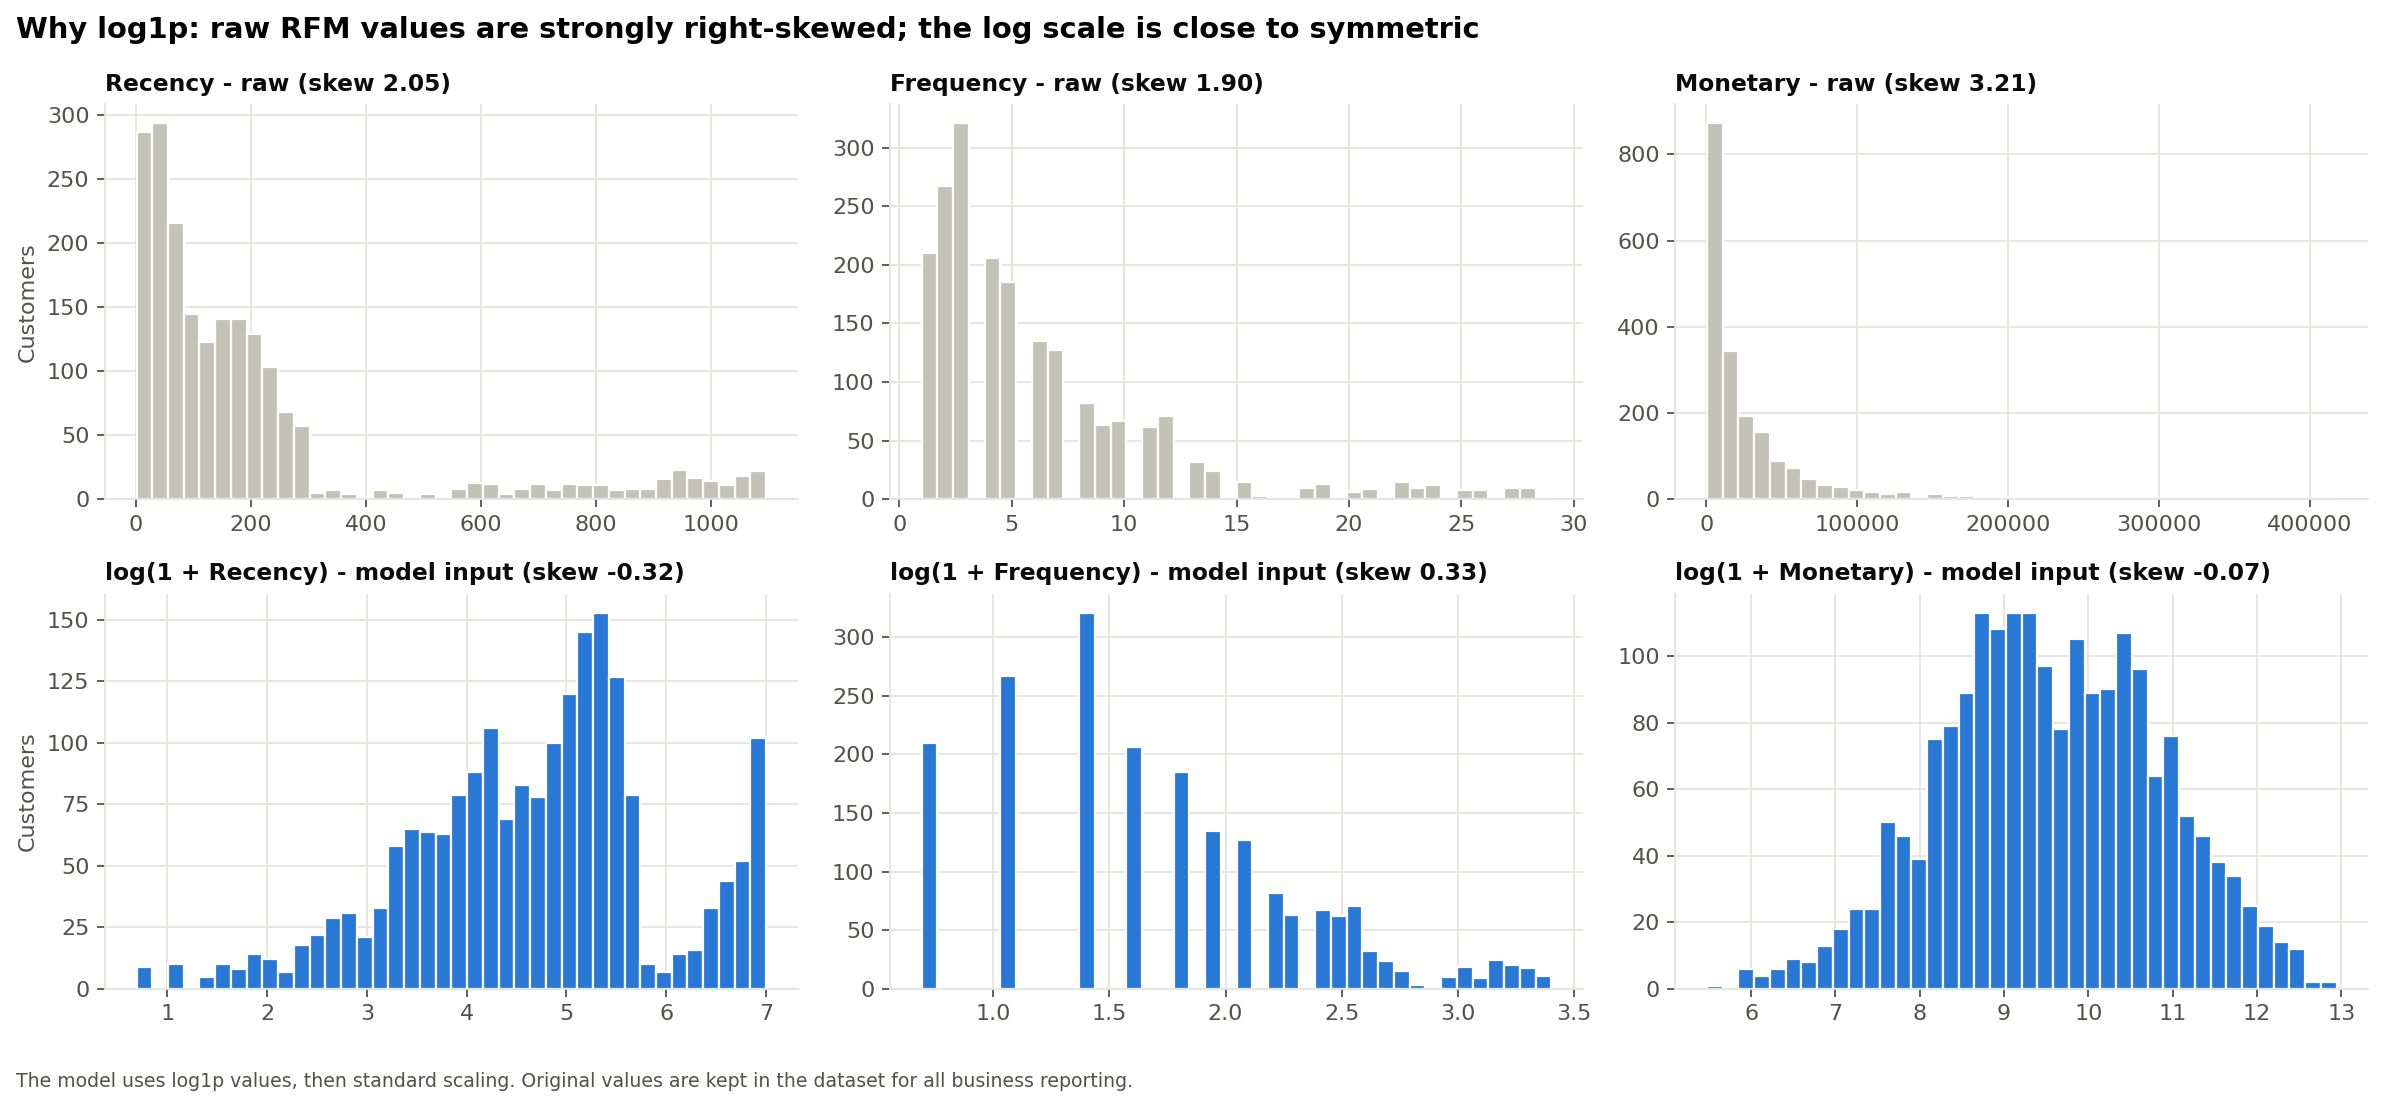

In [7]:
Image(str(FIG / "kmeans_feature_transformation.png"))

## 6. Feature Transformation

All three features are **strongly right-skewed**: skewness 2.05 for Recency, 1.90 for Frequency and 3.21 for Monetary. The largest Monetary value is 31 times the median.

`log1p` brings each feature close to symmetric (skewness −0.32, 0.32 and −0.07). Without it, K-Means would be pulled towards a handful of very large spenders, because it minimises *squared* distances. The transform is applied **because the measured skewness calls for it**, not by habit.

**Original values are kept** in the output dataset for all business reporting. The log values are used only as model inputs.

In [8]:
R['transformed'].describe().T

,count,mean,std,min,25%,50%,75%,max
log_Recency,"1,984.000",4.666,1.251,0.693,3.871,4.804,5.407,7.000
log_Frequency,"1,984.000",1.742,0.656,0.693,1.386,1.609,2.197,3.401
log_Monetary,"1,984.000",9.545,1.294,5.475,8.664,9.512,10.485,12.943


## 7. Feature Scaling

In [9]:
pre = R["preprocessor"]
print(pre)
print("Feature order:", list(pre.feature_names_in_))
pd.DataFrame(R["X_scaled"], columns=[f"scaled_log_{f}" for f in sg.CORE_FEATURES]).describe().T[["mean", "std", "min", "max"]]

Pipeline(steps=[('log1p',
                 FunctionTransformer(feature_names_out='one-to-one',
                                     func=<ufunc 'log1p'>,
                                     inverse_func=<ufunc 'expm1'>,
                                     validate=True)),
                ('scale', StandardScaler())])
Feature order: ['Recency', 'Frequency', 'Monetary']


,mean,std,min,max
scaled_log_Recency,-0.000,1.000,-3.176,1.867
scaled_log_Frequency,0.000,1.000,-1.598,2.529
scaled_log_Monetary,-0.000,1.000,-3.146,2.627


- **Why scale.** K-Means measures Euclidean distance. On raw values, Monetary (₹238 to ₹4.18 L) would dwarf Frequency (1 to 29 orders), and the clusters would effectively be formed on spend alone.
- **What was used.** `StandardScaler` puts each log feature on mean 0 and standard deviation 1, so all three contribute equally.
- **How it is saved.** The log1p and scaling steps are stored together as one sklearn `Pipeline` in `models/rfm_scaler.pkl`. New data is therefore always processed the same way, in the same feature order.

## 8. K-Means Model
`KMeans(n_clusters=K, random_state=42, n_init="auto")`: k-means++ initialisation with a fixed seed.

## 9. Optimal K Selection

In [10]:
R['k_selection'][['k', 'inertia', 'inertia_drop_%', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'min_cluster_share', 'stability_ari_mean', 'Eligible', 'Selected']]

,k,inertia,inertia_drop_%,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share,stability_ari_mean,Eligible,Selected
0,2,"3,256.389",NaN,0.378,0.988,"1,640.682",0.440,0.995,False,False
1,3,"2,431.331",25.337,0.327,1.064,"1,434.328",0.200,0.790,False,False
2,4,"1,780.247",26.779,0.353,0.951,"1,546.645",0.183,0.950,True,True
3,5,"1,526.617",14.247,0.312,1.042,"1,434.214",0.150,0.602,False,False
4,6,"1,298.222",14.961,0.325,0.960,"1,418.120",0.117,0.817,False,False
5,7,"1,141.388",12.081,0.326,0.972,"1,388.754",0.075,0.872,False,False
6,8,"1,089.052",4.585,0.306,0.973,"1,260.494",0.054,0.511,False,False
7,9,955.721,12.243,0.310,1.009,"1,290.619",0.054,0.714,False,False
8,10,855.554,10.481,0.315,0.979,"1,306.577",0.054,0.745,False,False


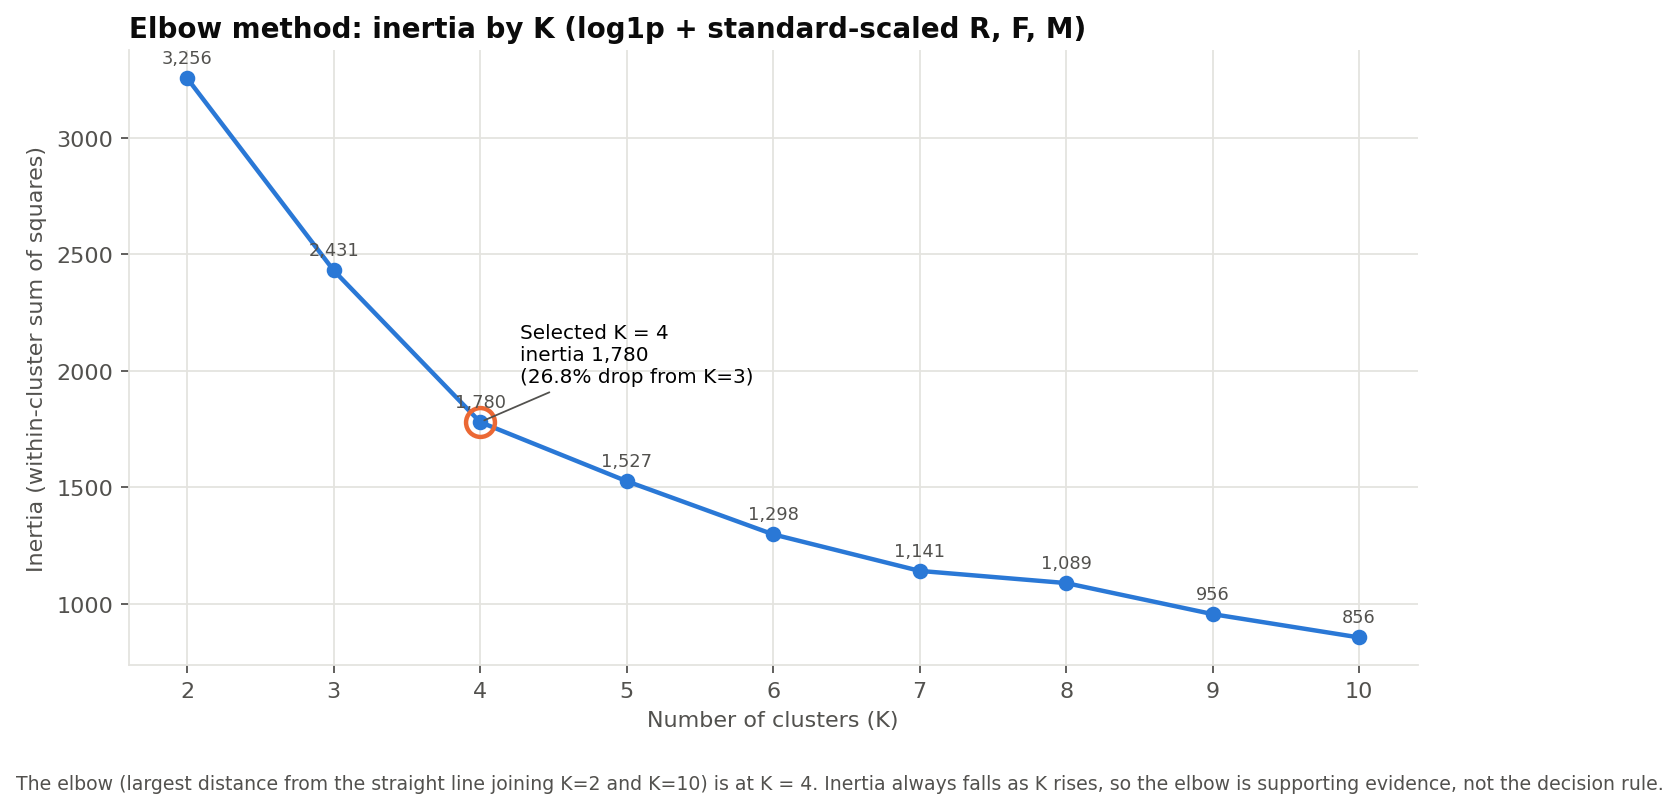

In [11]:
Image(str(FIG / "kmeans_elbow_curve.png"))

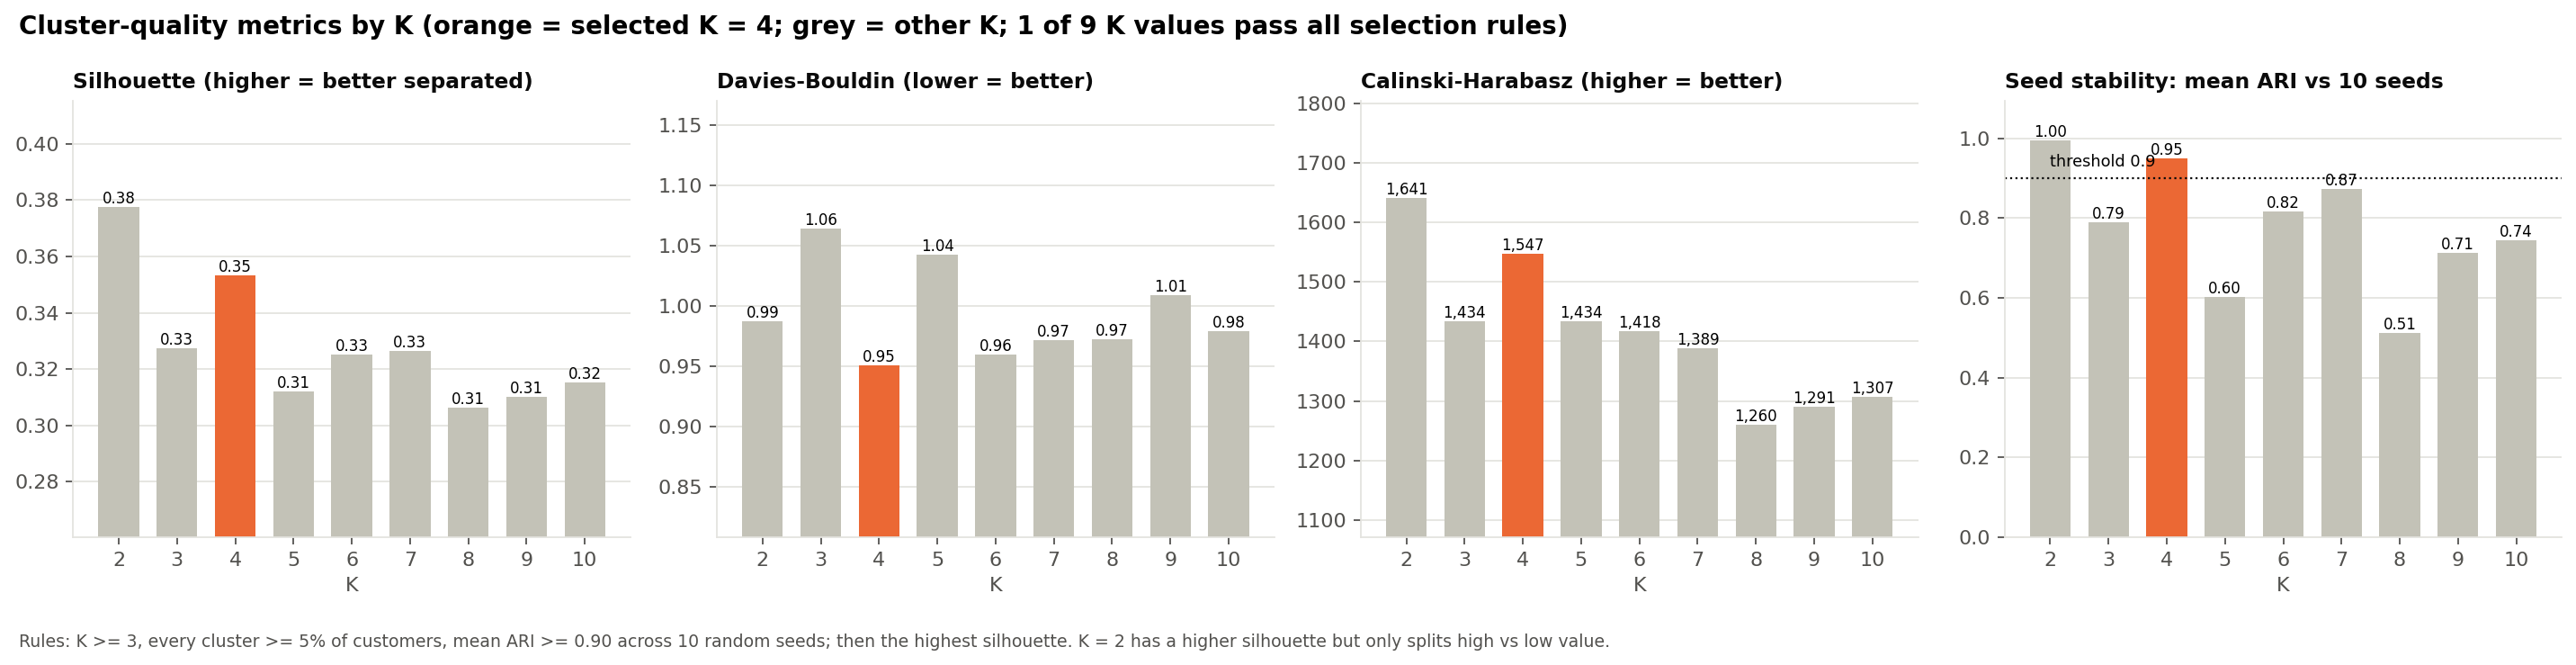

In [12]:
Image(str(FIG / "kmeans_silhouette_scores.png"))

**Selection rule, written down before looking at any cluster profiles:**

| Rule | Why |
|---|---|
| 1. K ≥ 3 | K = 2 can only split "higher" from "lower" value. It cannot separate recent customers from lapsed ones. |
| 2. Every cluster ≥ 5% of customers | Clusters have to be large enough to act on |
| 3. Mean seed-stability ARI ≥ 0.90 | Refitting with 10 other random seeds must give essentially the same partition |
| 4. Then the highest silhouette | Best separation among the options still eligible |

**Result: K = 4.**
- **Stability:** K = 4 is the only value from 3 to 10 whose clusters stay stable across seeds (ARI 0.95). K = 3, 5, 6 and 7 are reshuffled by the random start (ARI 0.60-0.87).
- **Supporting metrics:**
  - silhouette 0.353, second only to K = 2;
  - the **lowest Davies-Bouldin score of all K tested** (0.951);
  - the second-highest Calinski-Harabasz score (1,547);
  - the **elbow** is at K = 4, where inertia drops 26.8% from K = 3 but only 14.2% more from K = 4 to K = 5.

No single metric decided the choice. A silhouette of 0.35 means the clusters are **reasonably but not sharply** separated, which is typical for continuous customer behaviour.

## 10. Cluster Evaluation

In [13]:
display(R['final_metrics']); R['silhouette_by_cluster']

,Metric,Value
0,Selected K,4
1,Inertia (within-cluster sum of squares),"1,780.250"
2,Inertia with n_init=10 (check),"1,779.840"
3,Silhouette score,0.353
4,Calinski-Harabasz score,"1,546.600"
5,Davies-Bouldin score,0.951
6,"Seed stability (mean ARI, 10 seeds)",0.950
7,Smallest cluster share,0.183
8,Customers with negative silhouette,40
9,PC1 + PC2 explained variance (%),95.090


,Cluster_ID,Mean_Silhouette,Min_Silhouette,Share_Negative_Silhouette
0,0,0.408,-0.011,0.008
1,1,0.262,-0.057,0.044
2,2,0.387,0.019,0.000
3,3,0.344,-0.059,0.041


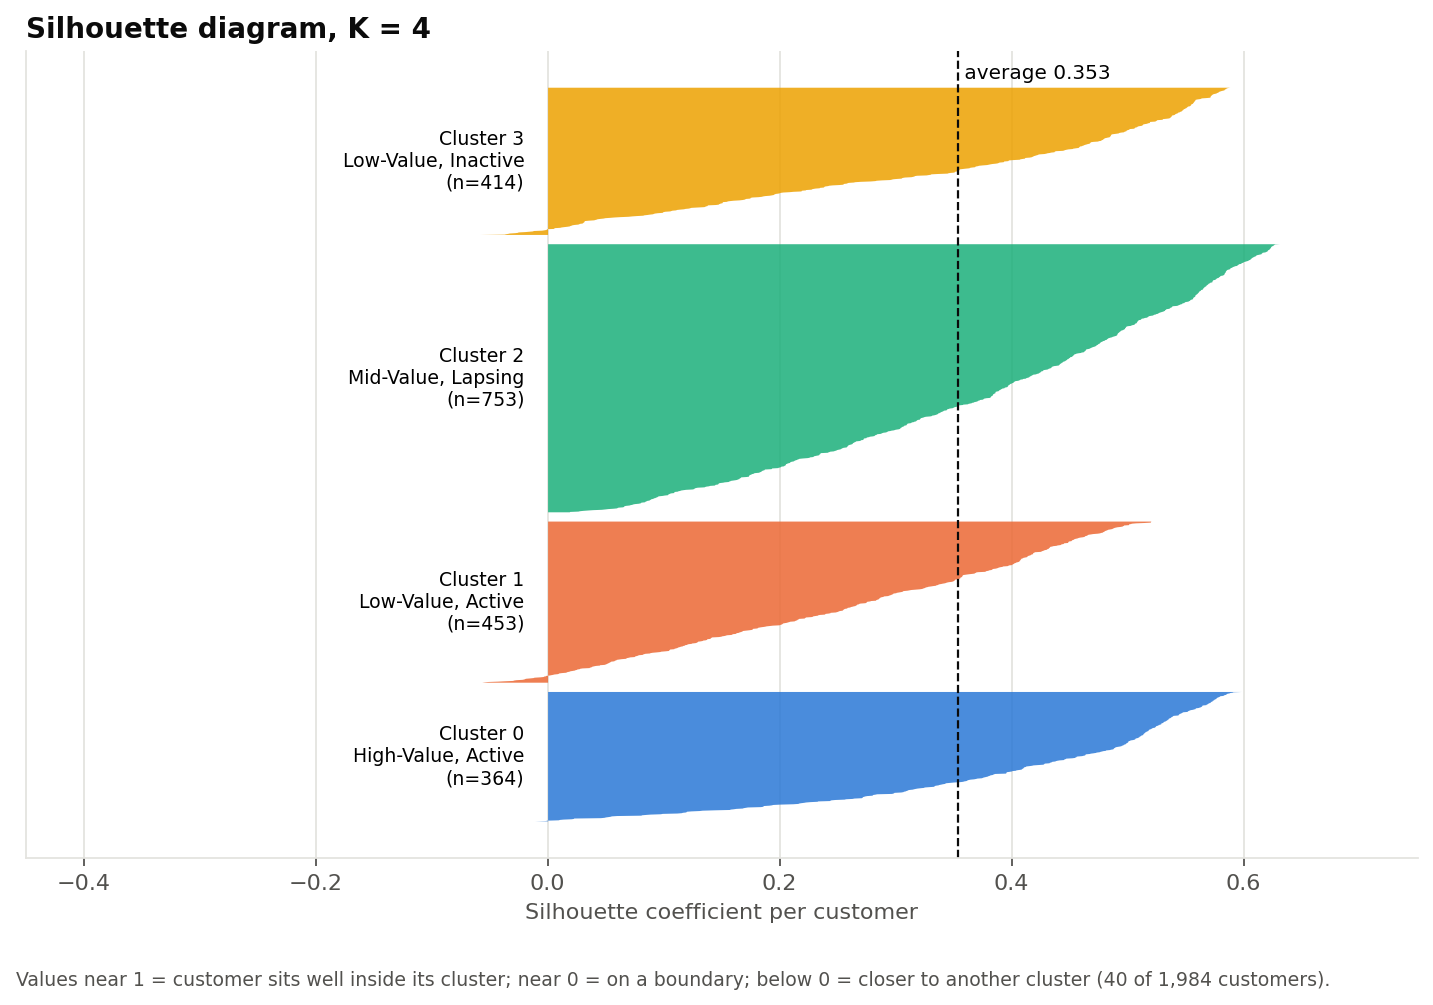

In [14]:
Image(str(FIG / "kmeans_silhouette_diagram.png"))

- All four clusters have a positive average silhouette, from 0.26 for Cluster 1 to 0.41 for Cluster 0.
- Only **40 of 1,984 customers (2.0%)** have a negative silhouette, meaning they are closer to a neighbouring cluster than to their own. They sit on boundaries between clusters.
- **No cluster is extremely small.** The smallest has 364 customers (18.3%), so there is no outlier-driven niche cluster to investigate.
- `n_init="auto"` uses one initialisation. A check with `n_init=10` reaches almost the same inertia (1,779.84 against 1,780.25), so a single initialisation is sufficient.

## 11. Final Clustering

In [15]:
print(seg["Cluster_ID"].value_counts().sort_index().to_frame("Customers").assign(Share=lambda t: (t.Customers / t.Customers.sum()).round(3)))
seg[["Customer_ID", "Recency", "Frequency", "Monetary", "RFM_Segment", "Cluster_ID", "Silhouette"]].head(8)

            Customers  Share
Cluster_ID                  
0                 364  0.183
1                 453  0.228
2                 753  0.380
3                 414  0.209


,Customer_ID,Recency,Frequency,Monetary,RFM_Segment,Cluster_ID,Silhouette
0,CUST-0001,10,5,"10,990.150",Potential Loyalists,1,0.212
1,CUST-0002,2,11,"43,213.650",Champions,0,0.412
2,CUST-0003,146,6,"22,484.850",Loyal Customers,2,0.604
3,CUST-0004,90,3,"36,127.400",Needs Attention,2,0.309
4,CUST-0005,62,11,"38,964.450",Champions,0,0.120
5,CUST-0006,77,11,"46,920.150",Champions,0,0.052
6,CUST-0007,29,6,"14,739.800",Potential Loyalists,2,0.060
7,CUST-0008,74,11,"87,405.800",Champions,0,0.226


In [16]:
# Reproducibility: reload the saved artefacts and re-predict every customer
pre_l = joblib.load(sg.PREPROCESSOR_FILE); km_l = joblib.load(sg.KMEANS_FILE)
same = (km_l.predict(pre_l.transform(seg[sg.CORE_FEATURES].astype(float))) == seg["Cluster_ID"]).all()
print("Saved model reproduces all assignments:", same)
json.loads(sg.MODEL_METADATA_FILE.read_text())

Saved model reproduces all assignments: True


{'dataset': 'SYNTHETIC DATA - generated for academic demonstration only',
 'input_file': 'data/processed/customer_rfm_segments.csv',
 'feature_order': ['Recency', 'Frequency', 'Monetary'],
 'preprocessing': 'log1p -> StandardScaler (sklearn Pipeline saved in rfm_scaler.pkl)',
 'model': "KMeans(n_clusters=4, random_state=42, n_init='auto')",
 'selected_k': 4,
 'selection_rules': {'min_k': 3,
  'min_cluster_share': 0.05,
  'min_stability_ari': 0.9,
  'then': 'highest silhouette'},
 'cluster_labels': {'0': 'High-Value, Active',
  '1': 'Low-Value, Active',
  '2': 'Mid-Value, Lapsing',
  '3': 'Low-Value, Inactive'},
 'pca': '2 components on the scaled matrix - visualisation only',
 'sklearn_version': '1.8.0',
 'reload_example': "import joblib, pandas as pd; pre = joblib.load('models/rfm_scaler.pkl'); km = joblib.load('models/kmeans_customer_segmentation.pkl'); X = df[['Recency','Frequency','Monetary']]; clusters = km.predict(pre.transform(X))"}

## 12. Cluster Profiling
The raw clusters (0-3) are profiled **before** any label is attached. All values are in original units.

In [17]:
cols = ["Cluster_ID", "Customer_Count", "Customer_%", "Average_Recency", "Median_Recency", "Average_Frequency", "Median_Frequency",
        "Average_Monetary", "Median_Monetary", "Total_Revenue", "Revenue_%", "Average_Order_Value", "Average_Quantity",
        "Average_Discount", "Profit_Margin", "Average_Categories", "Share_Existing_Before_2023", "Share_Recency_over_180d"]
R["profile"][cols].set_index("Cluster_ID").T

Cluster_ID,0,1,2,3
Customer_Count,364.000,453.000,753.000,414.000
Customer_%,18.347,22.833,37.954,20.867
Average_Recency,31.695,63.857,172.992,590.587
Median_Recency,28.000,57.000,168.000,623.500
Average_Frequency,14.882,2.751,6.238,2.058
Median_Frequency,13.000,3.000,6.000,2.000
Average_Monetary,"91,851.284","6,658.440","28,228.762","5,676.740"
Median_Monetary,"71,548.875","5,944.550","22,205.000","4,392.300"
Total_Revenue,"33,433,867.350","3,016,273.300","21,256,257.950","2,350,170.550"
Revenue_%,55.671,5.022,35.394,3.913


In [18]:
R['centroids'][['Cluster_ID', 'Recency_Profile', 'Frequency_Profile', 'Monetary_Profile', 'Recency_centre_original_units', 'Recency_cluster_median', 'Monetary_centre_original_units', 'Monetary_cluster_median']]

,Cluster_ID,Recency_Profile,Frequency_Profile,Monetary_Profile,Recency_centre_original_units,Recency_cluster_median,Monetary_centre_original_units,Monetary_cluster_median
0,0,very recent (~24 days),very high (~13.9 orders),"very high (~₹72,914)",24.000,28.000,"72,914.400","71,548.875"
1,1,recent (~48 days),low (~2.6 orders),"low (~₹5,152)",47.800,57.000,"5,152.000","5,944.550"
2,2,average (~149 days),average (~5.9 orders),"high (~₹22,744)",148.700,168.000,"22,743.800","22,205.000"
3,3,very long ago (~477 days),very low (~1.9 orders),"low (~₹4,011)",476.800,623.500,"4,010.700","4,392.300"


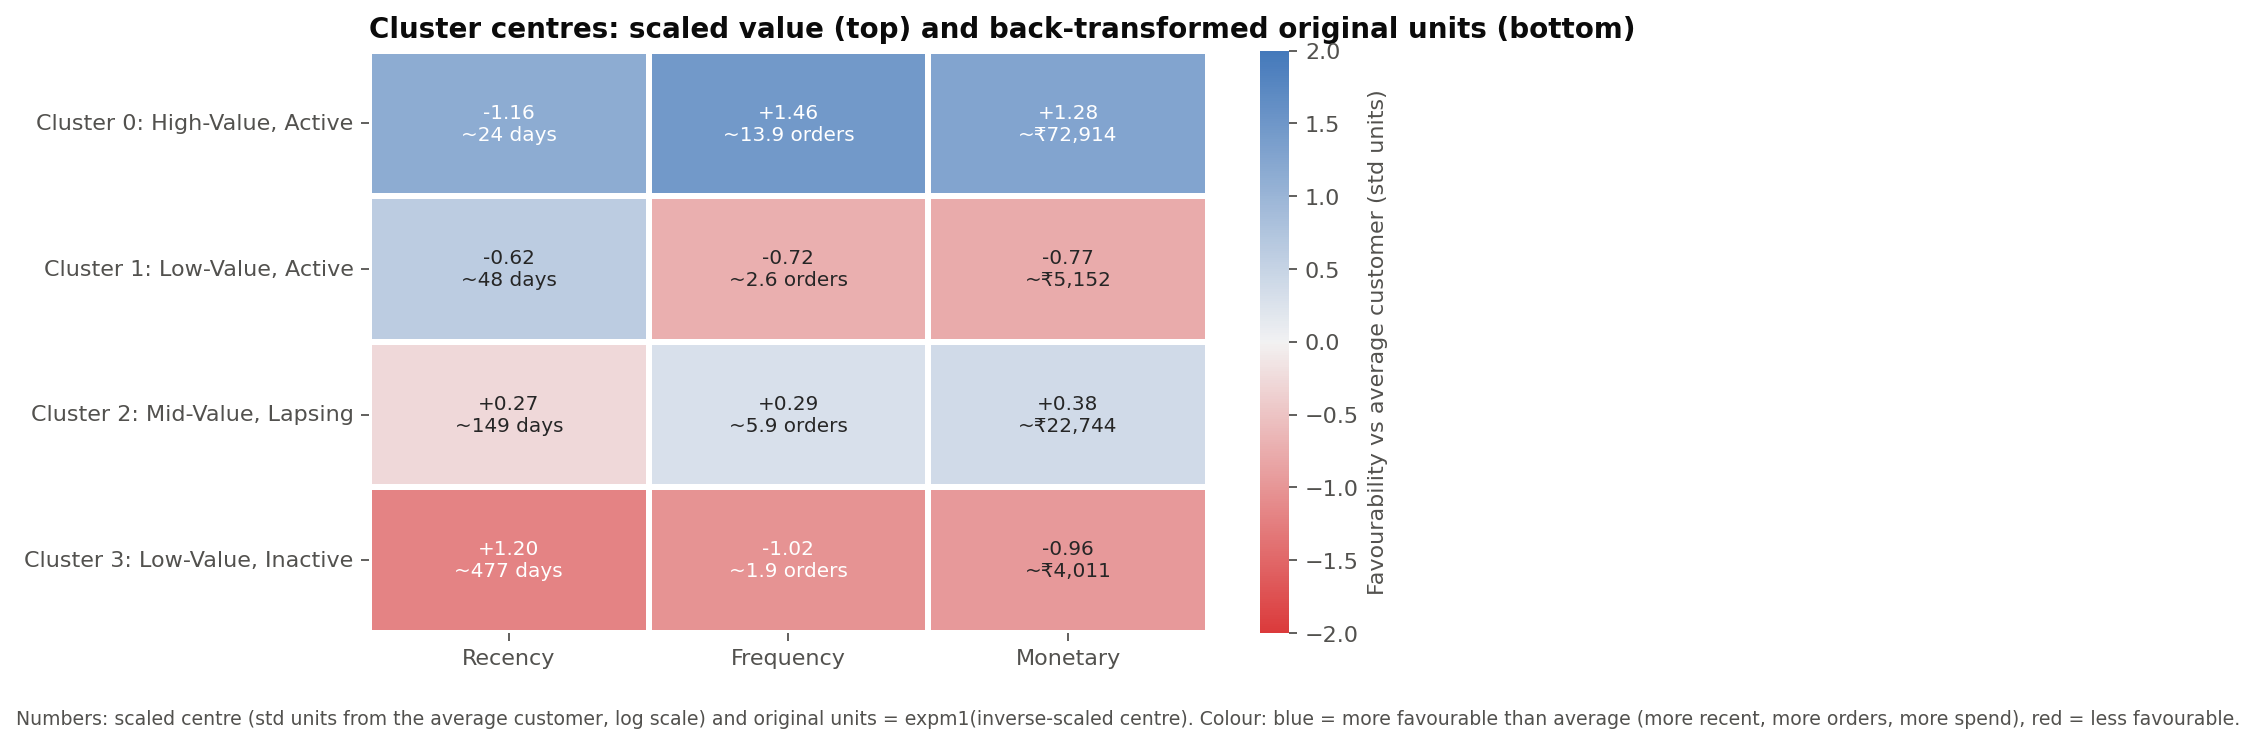

In [19]:
Image(str(FIG / "cluster_centroid_profile.png"))

**Centroids, correctly interpreted.** The model's centres are in *scaled log* units. For example, "+1.28" for Cluster 0's Monetary means 1.28 standard deviations above the average customer on the log scale, **not** ₹1.28.

To express the centres in business units they are converted back: first the scaling is inverted, then `expm1` undoes the log. This gives a geometric-mean-type centre, about ₹72,914 for Cluster 0, which sits close to the cluster's actual median of ₹71,549.

### 12.1 Business labels (assigned after profiling)

In [20]:
R['labels']

,Cluster_ID,Value_Level,Activity_Level,Business_Label,Basis
0,0,High-Value,Active,"High-Value, Active","median Monetary ₹71,549 (terciles ₹7,552 / ₹26,089); median Recency 28 days (Active <= 83, Inactive >= 255); median 13 orders"
1,1,Low-Value,Active,"Low-Value, Active","median Monetary ₹5,945 (terciles ₹7,552 / ₹26,089); median Recency 57 days (Active <= 83, Inactive >= 255); median 3 orders"
2,2,Mid-Value,Lapsing,"Mid-Value, Lapsing","median Monetary ₹22,205 (terciles ₹7,552 / ₹26,089); median Recency 168 days (Active <= 83, Inactive >= 255); median 6 orders"
3,3,Low-Value,Inactive,"Low-Value, Inactive","median Monetary ₹4,392 (terciles ₹7,552 / ₹26,089); median Recency 624 days (Active <= 83, Inactive >= 255); median 2 orders"


Labels come from **two measured dimensions only**, using cut-offs from the data itself:
- **Value:** the cluster's median Monetary against the all-customer terciles (₹7,552 and ₹26,089).
- **Activity:** the cluster's median Recency against the Step 5 recency-score edges: **Active** if 83 days or less, **Inactive** if 255 days or more, **Lapsing** in between.

| Cluster_ID | Business label | Why |
|---|---|---|
| 0 | High-Value, Active | Median spend ₹71,549 (top tercile); median recency 28 days; median 13 orders |
| 1 | Low-Value, Active | Median spend ₹5,945 (bottom tercile); median recency 57 days; median 3 orders |
| 2 | Mid-Value, Lapsing | Median spend ₹22,205 (middle tercile); median recency 168 days; median 6 orders |
| 3 | Low-Value, Inactive | Median spend ₹4,392 (bottom tercile); median recency 624 days; median 2 orders |

## 13. Cluster Visualization

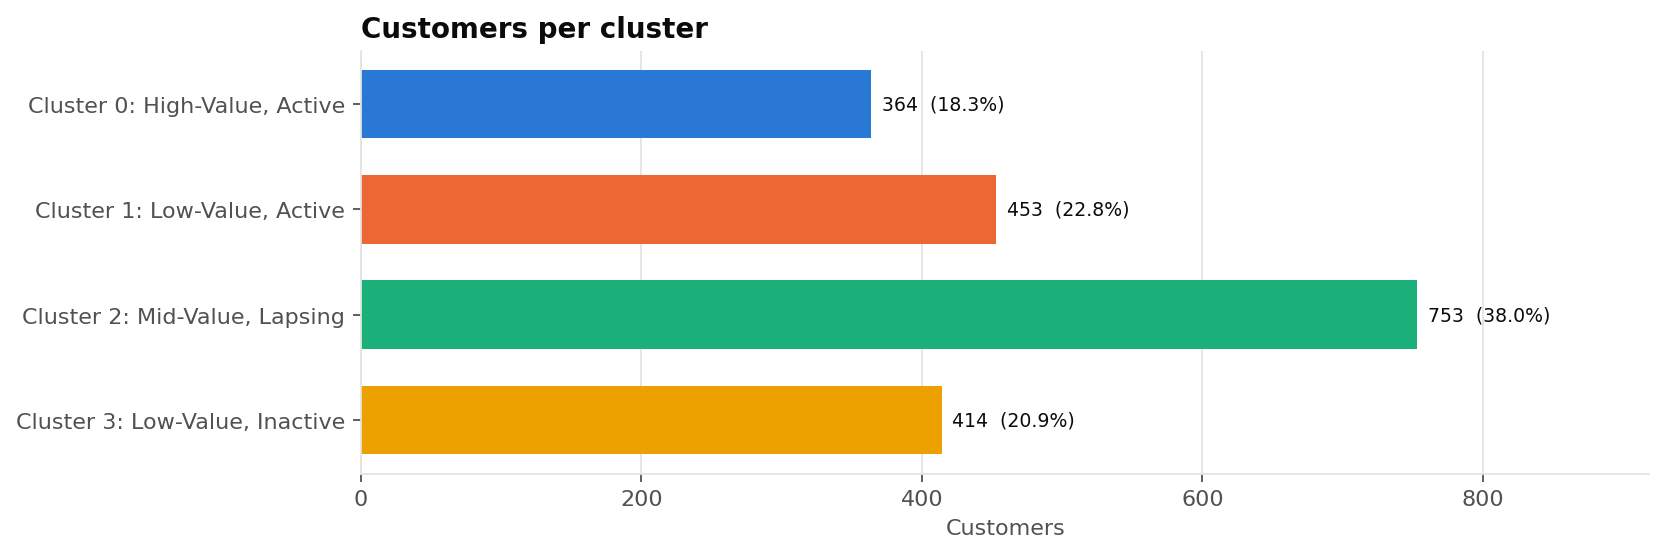

In [21]:
Image(str(FIG / "cluster_distribution.png"))

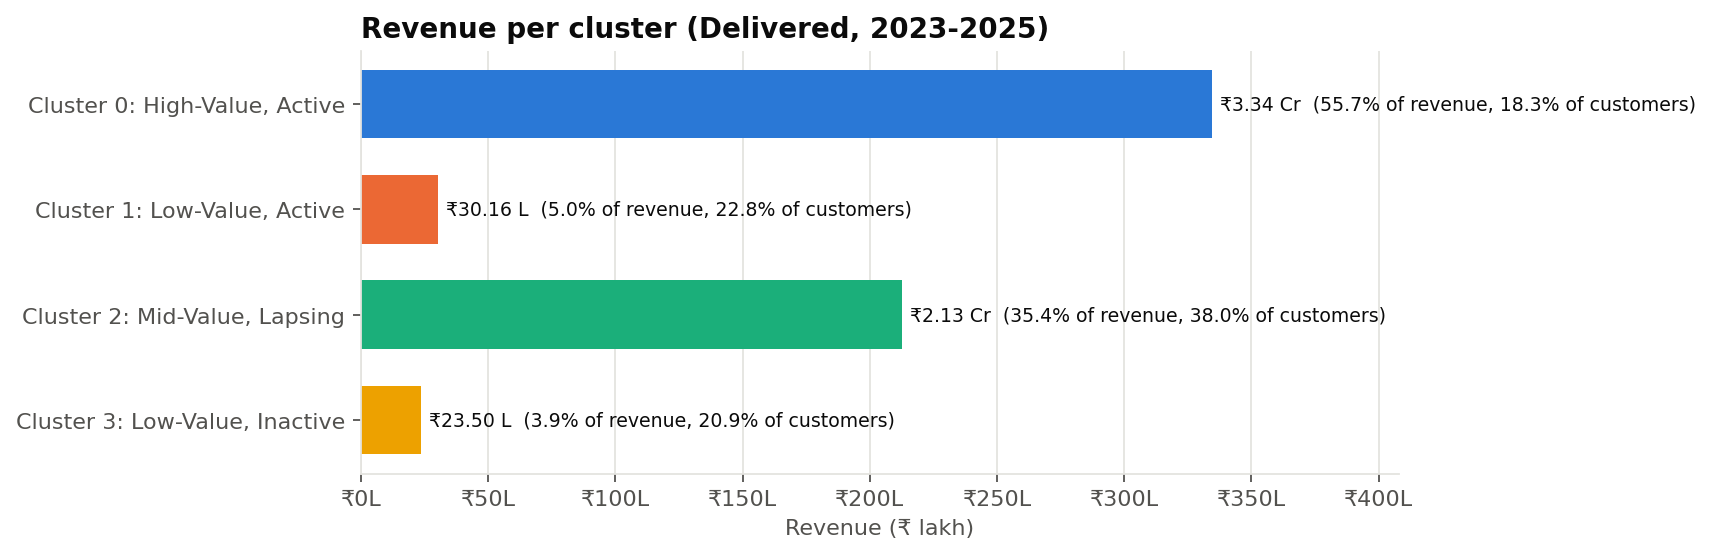

In [22]:
Image(str(FIG / "cluster_revenue.png"))

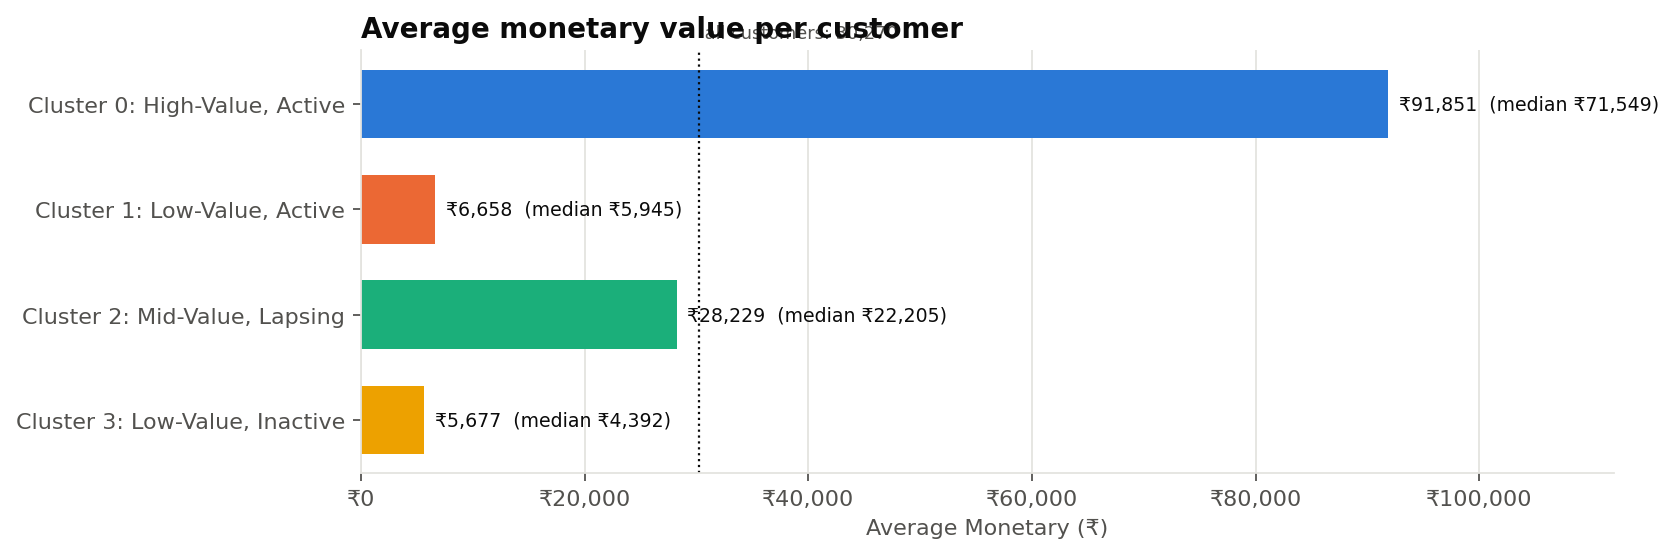

In [23]:
Image(str(FIG / "cluster_monetary.png"))

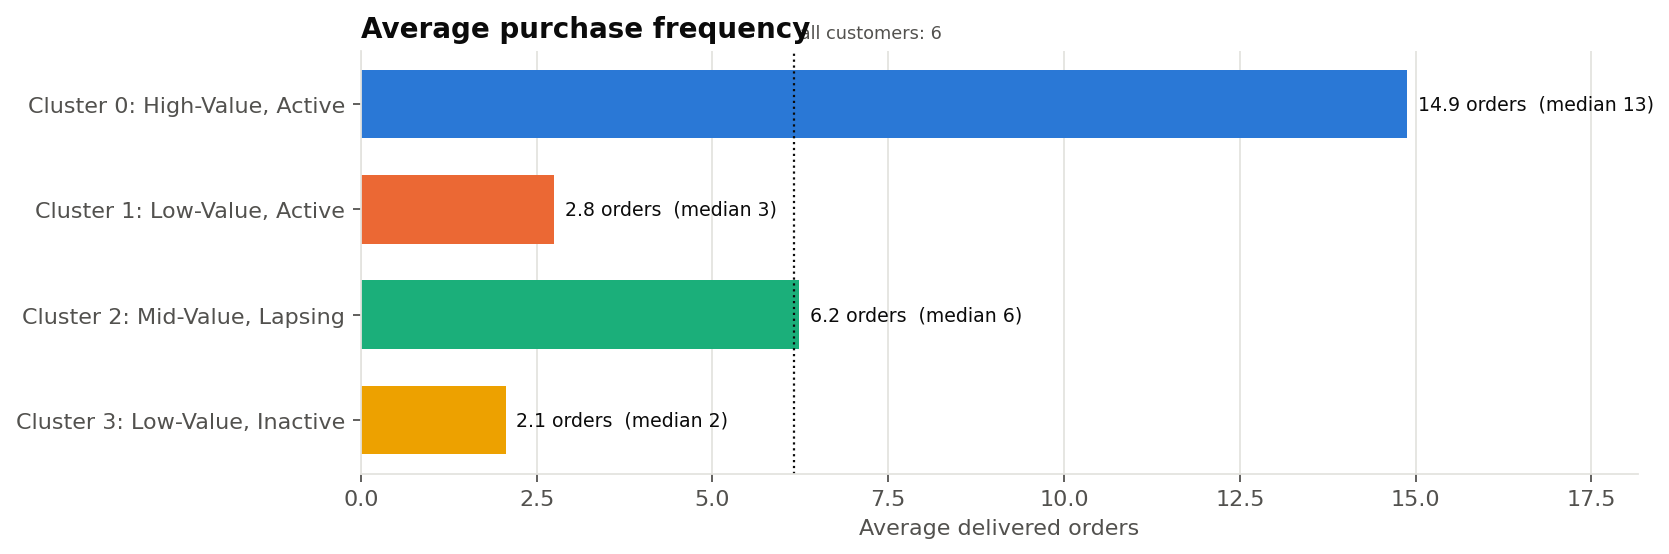

In [24]:
Image(str(FIG / "cluster_frequency.png"))

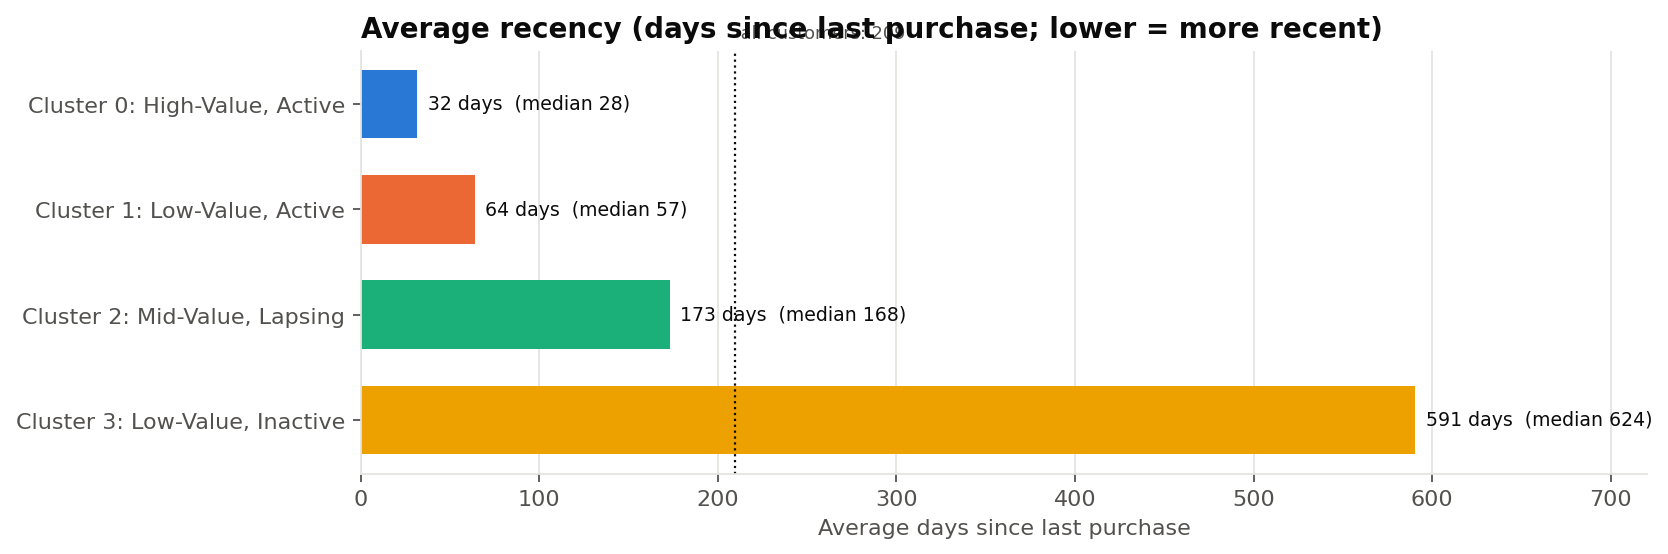

In [25]:
Image(str(FIG / "cluster_recency.png"))

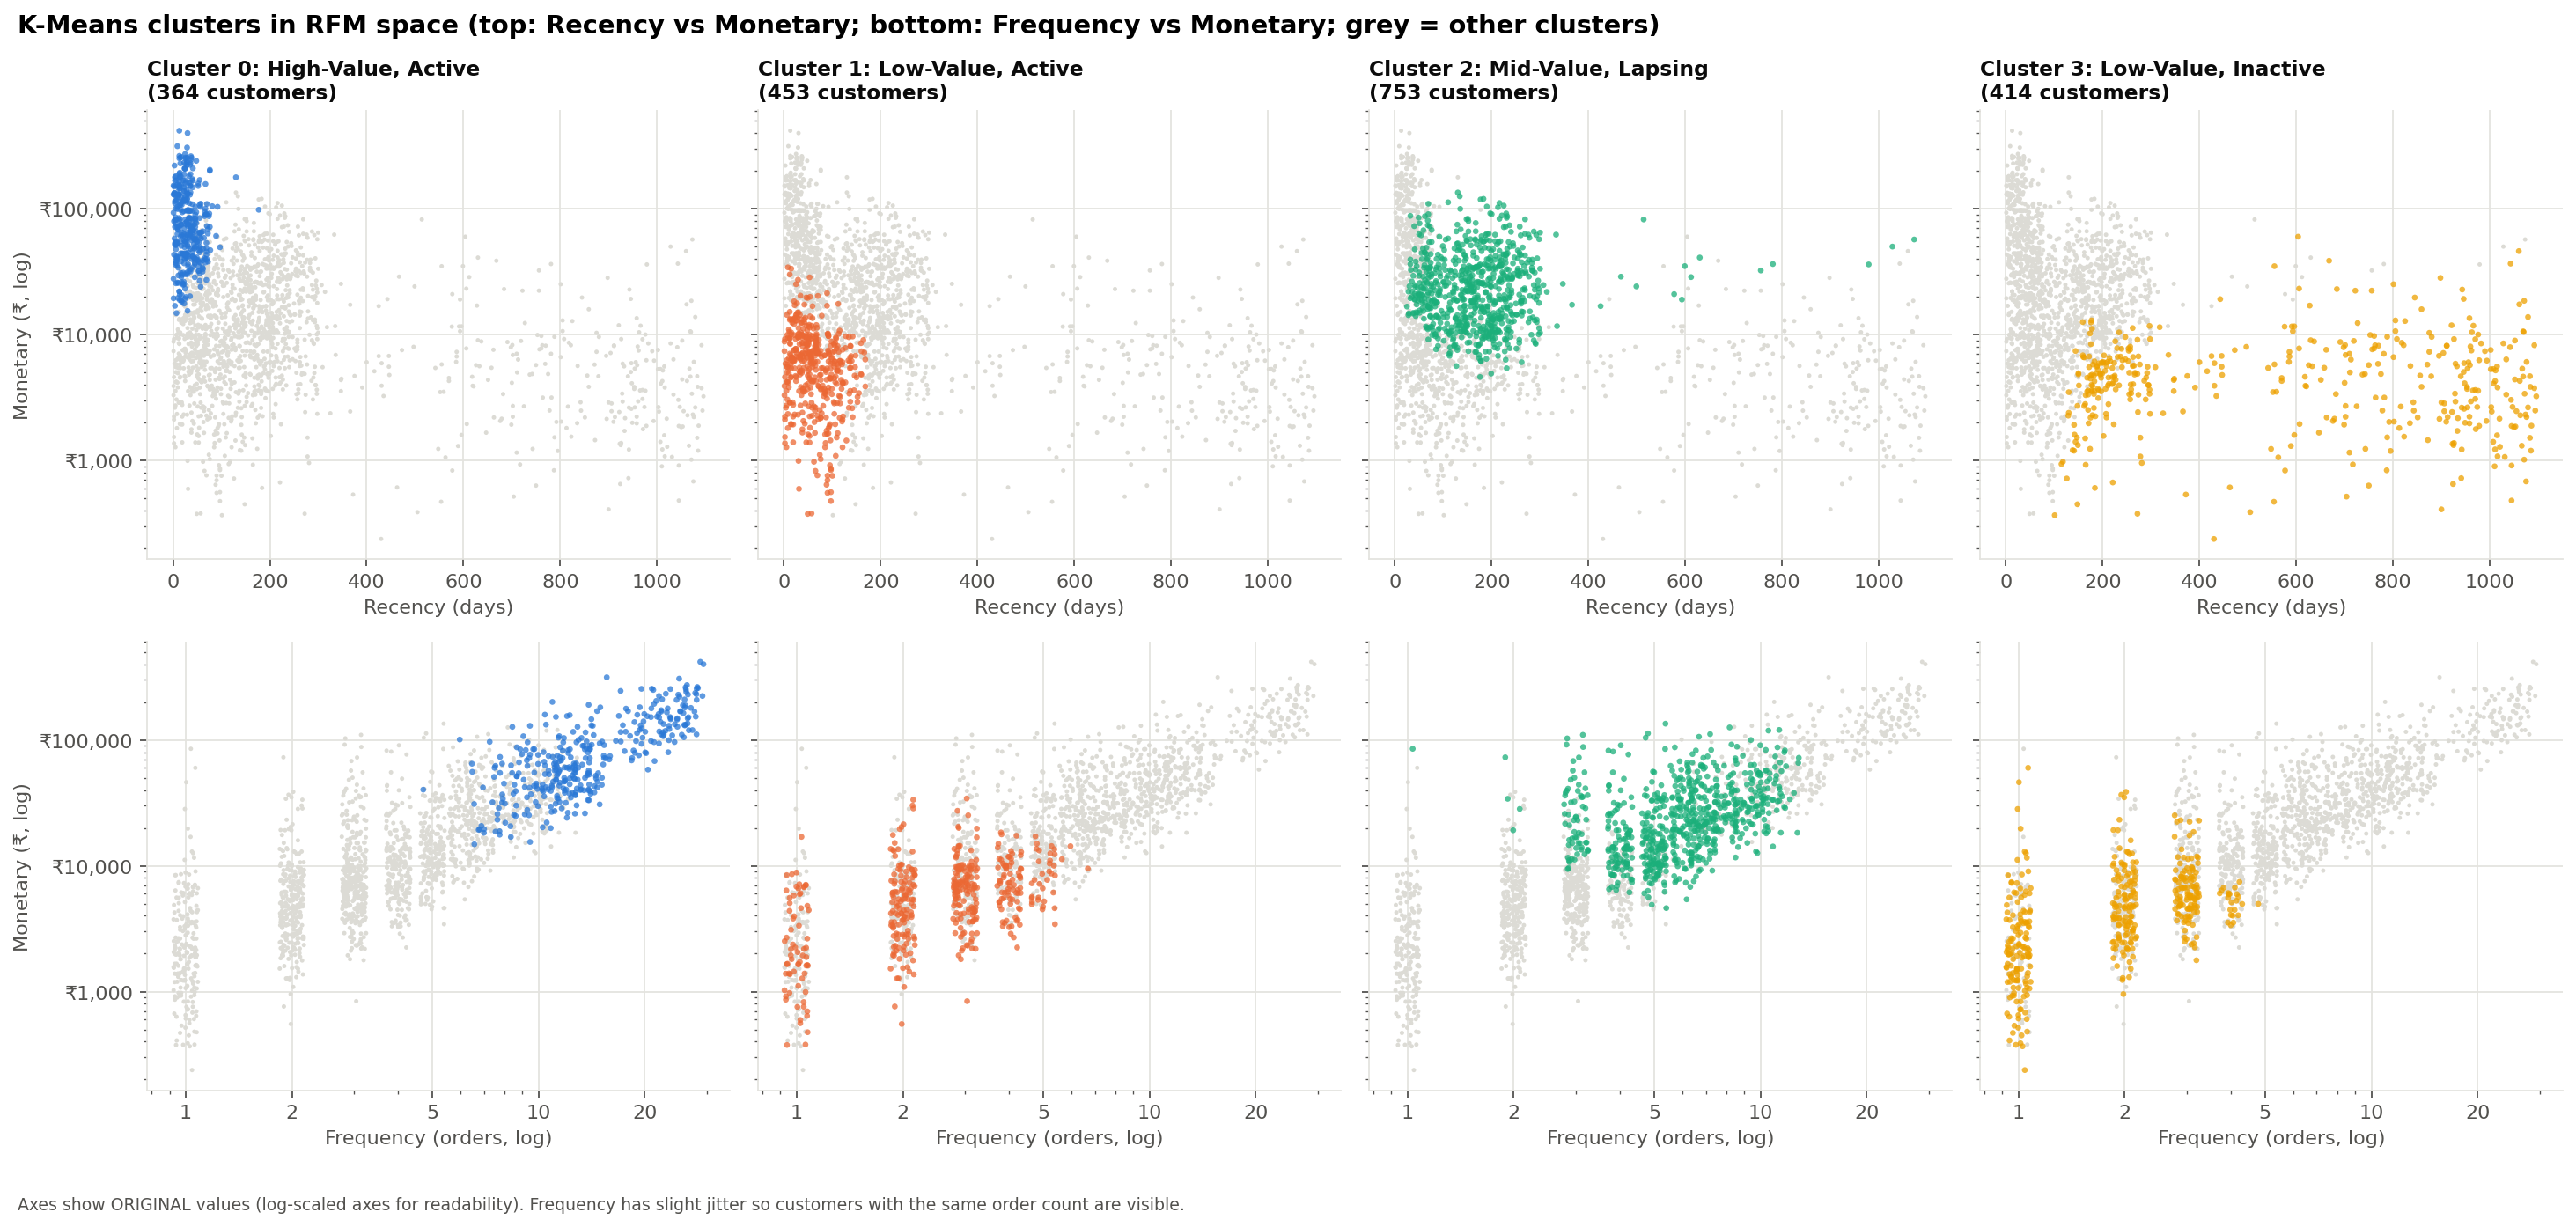

In [26]:
Image(str(FIG / "cluster_rfm_scatter.png"))

### 13.1 PCA (visualisation only)

In [27]:
R['pca_summary']

,Component,Explained_Variance_%,Loading_of,PC1,PC2
0,PC1,71.499,NaN,NaN,NaN
1,PC2,23.589,NaN,NaN,NaN
2,Total (PC1+PC2),95.089,NaN,NaN,NaN
3,NaN,NaN,log_Recency,-0.453,0.888
4,NaN,NaN,log_Frequency,0.638,0.264
5,NaN,NaN,log_Monetary,0.622,0.376


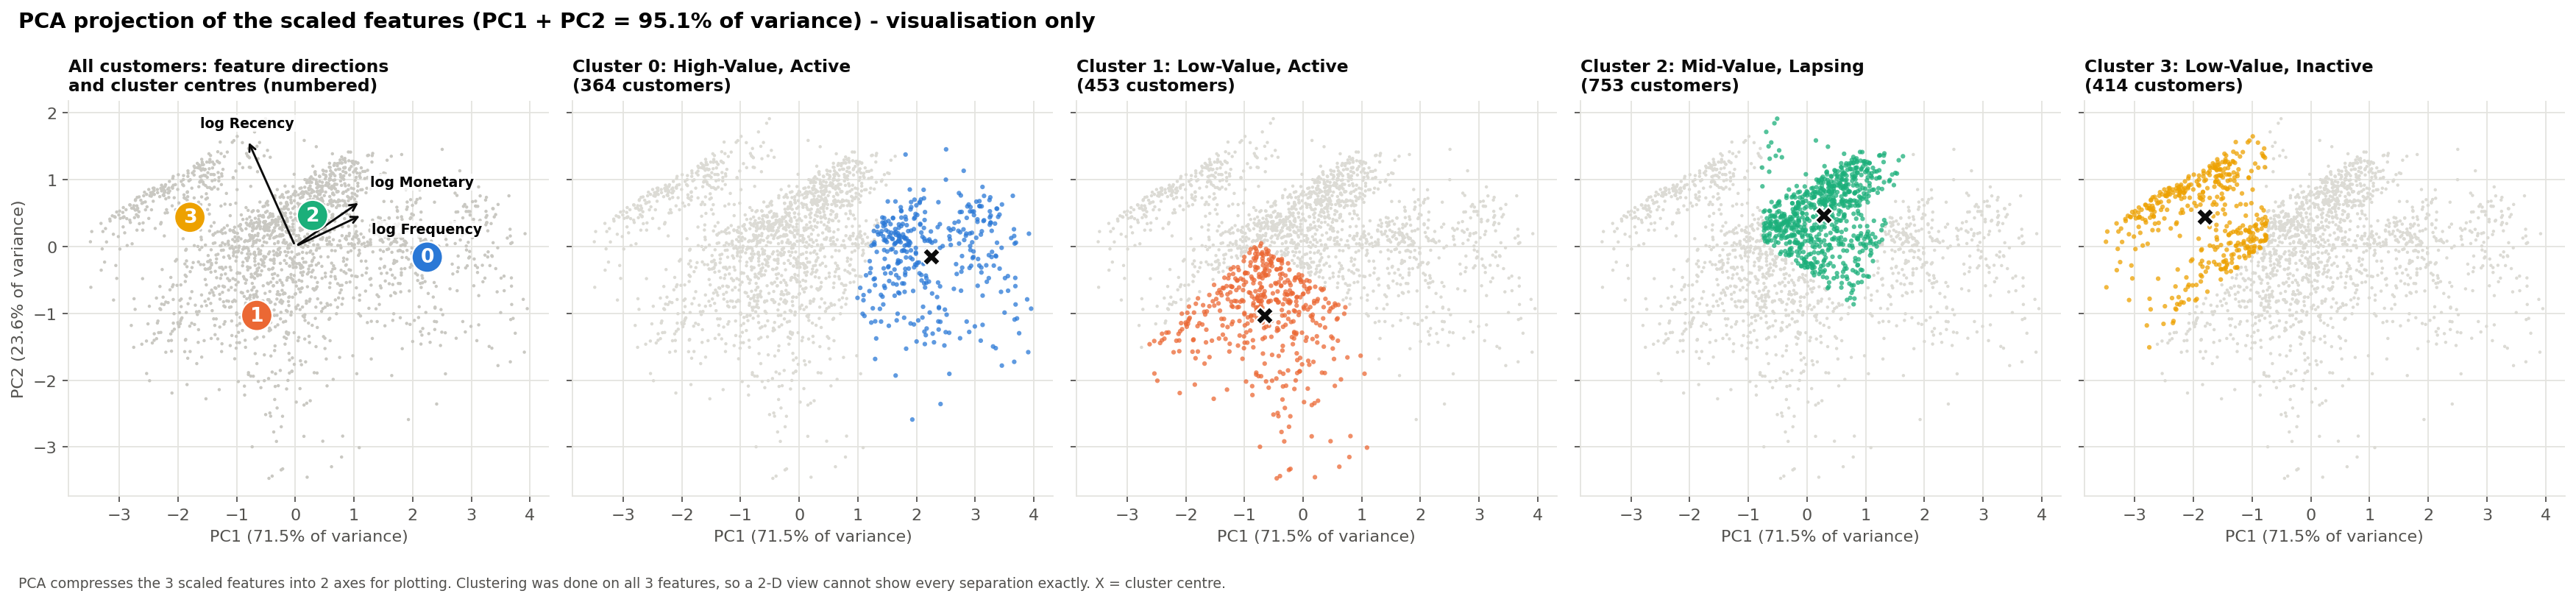

In [28]:
Image(str(FIG / "cluster_pca_visualization.png"))

- **What each component means.** PC1 explains **71.5%** of the variance. It loads positively on log Frequency (0.64) and log Monetary (0.62) and negatively on log Recency (−0.45), so it reads as an overall **value-and-activity** axis. PC2 explains **23.6%** and is dominated by Recency (0.89).
- **How much is kept.** Together the two components hold 95.1% of the variance, so the 2-D picture is faithful but not perfect.
- **What it is used for.** PCA is used **only for plotting**. The clusters were formed on all three scaled features, and some points that look close together in 2-D are further apart in 3-D.
- **What the plot shows.** The four clusters occupy clearly different regions: Cluster 0 on the right (high value), Cluster 3 on the left (inactive), Cluster 1 at the bottom (recent, low value) and Cluster 2 in the middle (mid value, lapsing).

## 14. Comparison with RFM Segments

In [29]:
R['comparison']['crosstab']

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
RFM_Segment,,,,
Champions,324,0,10,0
Loyal Customers,39,0,201,0
Potential Loyalists,0,102,50,0
Recent Customers,0,91,0,0
Promising,0,110,0,0
Needs Attention,0,28,95,0
About to Sleep,0,118,0,25
Can't Lose Them,1,0,78,0
At Risk,0,0,256,7


In [30]:
R['comparison']['row_pct']

,Cluster 0,Cluster 1,Cluster 2,Cluster 3
RFM_Segment,,,,
Champions,97.000,0.000,3.000,0.000
Loyal Customers,16.200,0.000,83.800,0.000
Potential Loyalists,0.000,67.100,32.900,0.000
Recent Customers,0.000,100.000,0.000,0.000
Promising,0.000,100.000,0.000,0.000
Needs Attention,0.000,22.800,77.200,0.000
About to Sleep,0.000,82.500,0.000,17.500
Can't Lose Them,1.300,0.000,98.700,0.000
At Risk,0.000,0.000,97.300,2.700


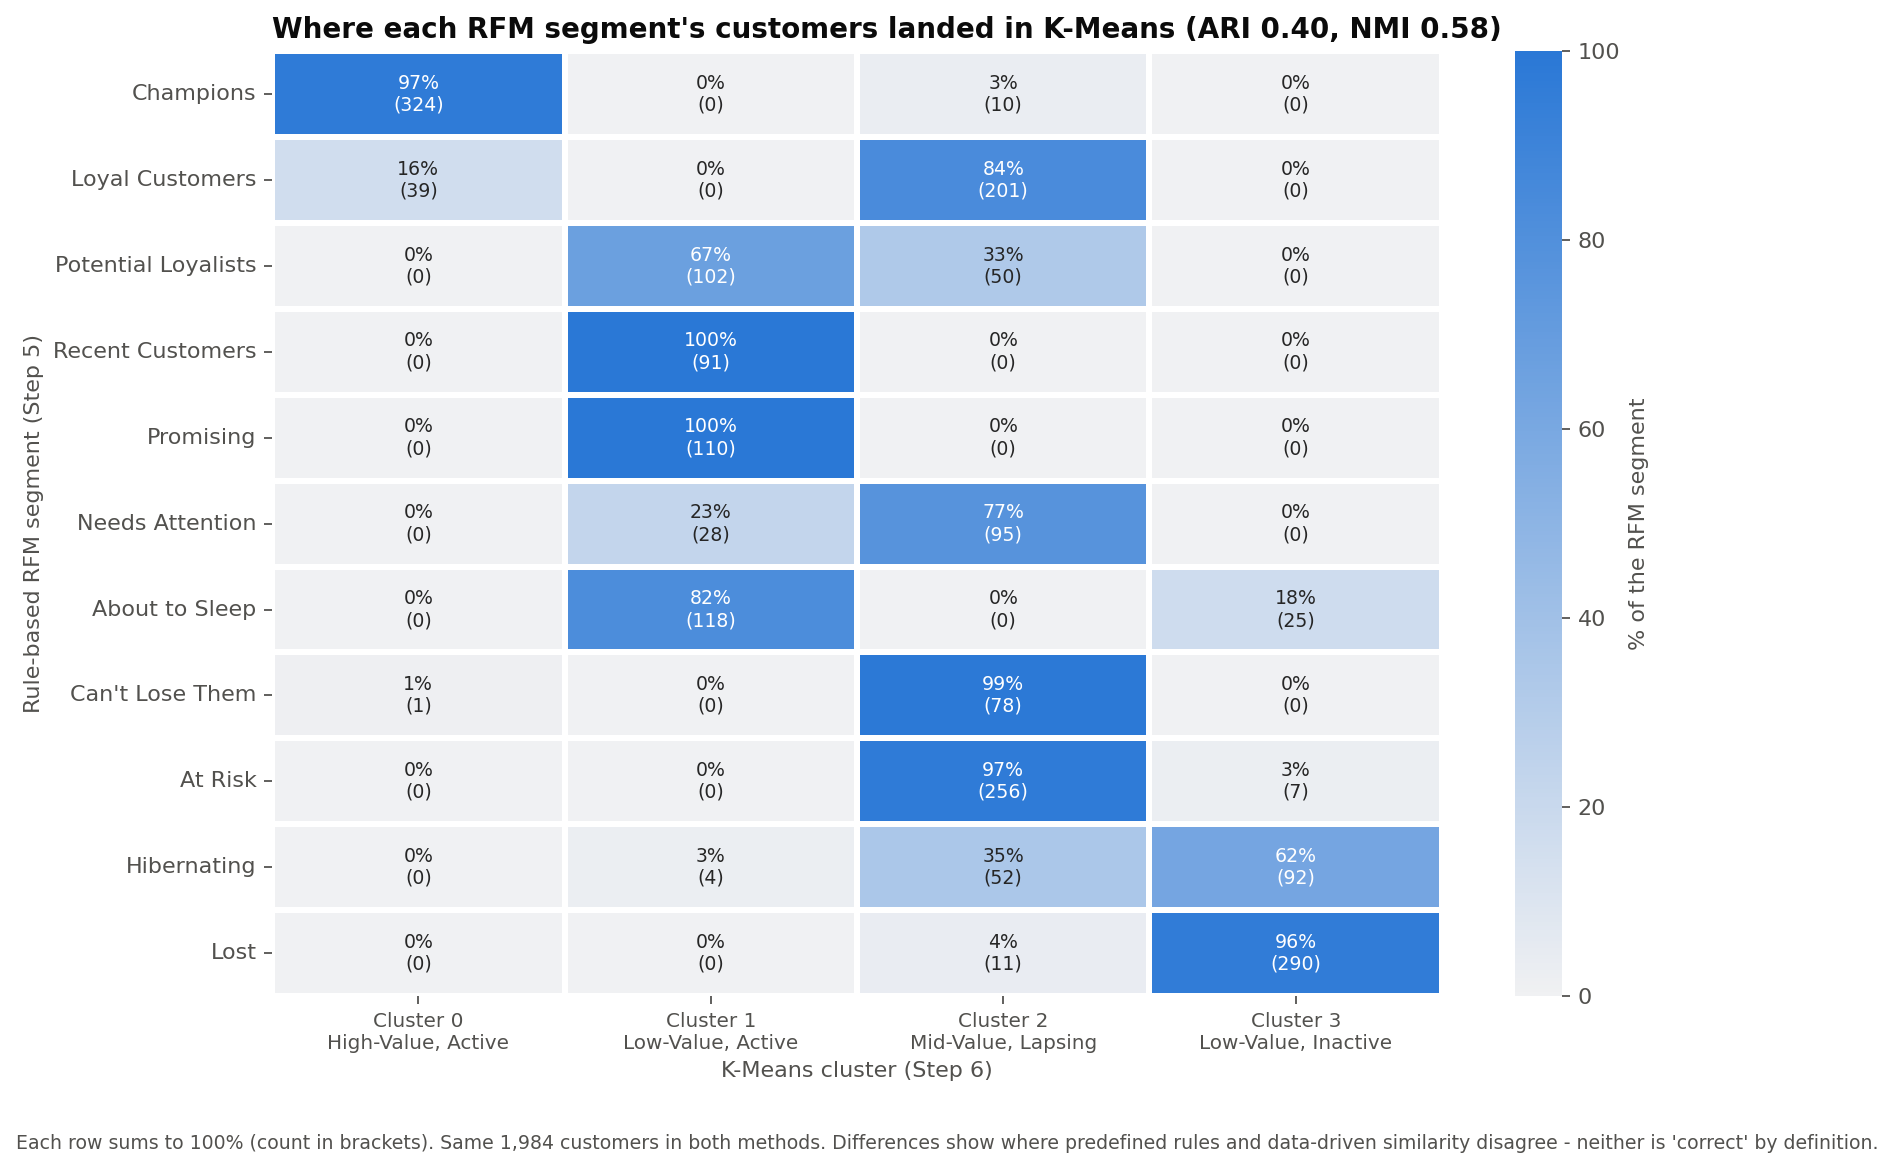

In [31]:
Image(str(FIG / "rfm_vs_ml_cluster_heatmap.png"))

In [32]:
display(R['comparison']['by_segment']); display(R['comparison']['by_cluster']); R['comparison']['agreement']

,RFM_Segment,Customers,Dominant_Cluster,Dominant_Cluster_Label,Share_in_Dominant_%,Clusters_with_>=10%,Pattern
0,Champions,334,Cluster 0,"High-Value, Active",97.000,1,Mostly one cluster
1,Loyal Customers,240,Cluster 2,"Mid-Value, Lapsing",83.800,2,Mostly one cluster
2,Potential Loyalists,152,Cluster 1,"Low-Value, Active",67.100,2,Splits across 2 clusters
3,Recent Customers,91,Cluster 1,"Low-Value, Active",100.000,1,Mostly one cluster
4,Promising,110,Cluster 1,"Low-Value, Active",100.000,1,Mostly one cluster
5,Needs Attention,123,Cluster 2,"Mid-Value, Lapsing",77.200,2,Splits across 2 clusters
6,About to Sleep,143,Cluster 1,"Low-Value, Active",82.500,2,Mostly one cluster
7,Can't Lose Them,79,Cluster 2,"Mid-Value, Lapsing",98.700,1,Mostly one cluster
8,At Risk,263,Cluster 2,"Mid-Value, Lapsing",97.300,1,Mostly one cluster
9,Hibernating,148,Cluster 3,"Low-Value, Inactive",62.200,2,Splits across 2 clusters


,Cluster,Business_Label,Customers,RFM_Segments_with_>=10%,Composition (top 3)
0,Cluster 0,"High-Value, Active",364,2,Champions 89%; Loyal Customers 11%; Can't Lose Them 0%
1,Cluster 1,"Low-Value, Active",453,4,About to Sleep 26%; Promising 24%; Potential Loyalists 23%
2,Cluster 2,"Mid-Value, Lapsing",753,4,At Risk 34%; Loyal Customers 27%; Needs Attention 13%
3,Cluster 3,"Low-Value, Inactive",414,2,Lost 70%; Hibernating 22%; About to Sleep 6%


,Measure,Value
0,Adjusted Rand Index (RFM segment vs cluster),0.395
1,Normalized Mutual Information,0.579
2,ARI (RFM value-activity group vs cluster),0.449
3,Customers compared,"1,984.000"


**Where the two methods agree:**
- 97% of **Champions** are in Cluster 0 (High-Value, Active).
- 96% of **Lost** customers are in Cluster 3 (Low-Value, Inactive).
- All **Recent Customers** and all **Promising** customers are in Cluster 1.
- 97% of **At Risk** and 99% of **Can't Lose Them** customers are in Cluster 2.

**Where they differ:**
- **Loyal Customers:** 84% are placed in Cluster 2 (Mid-Value, Lapsing) alongside At Risk customers. The RFM rules call a customer with R = 3 (84-162 days) "Loyal", but in the transformed feature space those customers sit closer to the lapsing group.
- **Segments that split between clusters:** Potential Loyalists (67% / 33%), Needs Attention (77% / 23%) and Hibernating (62% / 35%).
- **Clusters that combine several segments:** Cluster 1 mixes About to Sleep, Promising, Potential Loyalists and Recent Customers. Cluster 2 combines At Risk, Loyal Customers, Can't Lose Them and Needs Attention.

**Overall agreement** is moderate: ARI 0.40 and NMI 0.58. That is expected when 11 rule-based segments are compared with 4 data-driven clusters.

**Neither method is "correct".**
- The RFM rules draw fixed cut-offs on quintile scores.
- K-Means groups customers by similarity.

The comparison shows where the rule boundaries do and do not match the natural structure of the data.

## 15. Business Interpretation

In [33]:
R['insights']

,Cluster,Customer Profile,Evidence,Business Interpretation
0,Cluster 0,"High-Value, Active: median 13 orders, median spend ₹71,549, median recency 28 days","364 customers (18.3%) -> ₹3.34 Cr (55.7% of revenue, 3.03x their customer share); AOV ₹6,172; avg discount 10.6% (all customers 13.7%); 0.0% inactive > 180 days; RFM ...","Core revenue base - retention and service quality matter most; small in count, large in value"
1,Cluster 1,"Low-Value, Active: median 3 orders, median spend ₹5,945, median recency 57 days","453 customers (22.8%) -> ₹30.16 L (5.0% of revenue, 0.22x their customer share); AOV ₹2,421; avg discount 16.5% (all customers 13.7%); 0.0% inactive > 180 days; RFM m...",Recently active but not yet high value - development / cross-sell potential
2,Cluster 2,"Mid-Value, Lapsing: median 6 orders, median spend ₹22,205, median recency 168 days","753 customers (38.0%) -> ₹2.13 Cr (35.4% of revenue, 0.93x their customer share); AOV ₹4,525; avg discount 13.2% (all customers 13.7%); 44.0% inactive > 180 days; RFM...",Proven spenders whose activity has dropped - measurable win-back opportunity; size it with CLV (Step 7)
3,Cluster 3,"Low-Value, Inactive: median 2 orders, median spend ₹4,392, median recency 624 days","414 customers (20.9%) -> ₹23.50 L (3.9% of revenue, 0.19x their customer share); AOV ₹2,758; avg discount 14.2% (all customers 13.7%); 87.2% inactive > 180 days; RFM ...",Low spend and long inactive - low priority for paid retention; low-cost reactivation only


In [34]:
R['questions']

,Question,Answer (from data)
0,Q1. How many ML customer clusters were selected?,"K = 4. It passed all three rules (K >= 3, smallest cluster 18.3% >= 5%, seed stability ARI 0.95 >= 0.90) and has the highest silhouette among eligible K (0.353); it a..."
1,Q2. What characteristics define each cluster?,"Cluster 0 (High-Value, Active): 364 customers, median recency 28 d, median 13 orders, median spend ₹71,549 | Cluster 1 (Low-Value, Active): 453 customers, median rece..."
2,Q3. Which clusters have the highest monetary value?,"Cluster 0 (High-Value, Active): average ₹91,851, median ₹71,549 per customer."
3,Q4. Which clusters have the highest purchase frequency?,"Cluster 0 (High-Value, Active): average 14.9 orders (median 13)."
4,Q5. Which clusters have the most recent purchases?,"Cluster 0 (High-Value, Active): median recency 28 days (100.0% bought within 180 days)."
5,Q6. Which clusters contribute the most revenue?,"Cluster 0 (High-Value, Active): ₹3.34 Cr (55.7%) from 18.3% of customers."
6,Q7. Are there clusters containing high-value but less-recent customers?,"Yes: Cluster 2 (Mid-Value, Lapsing) - median spend ₹22,205 (above the all-customer median ₹13,513) with median recency 168 days (above the median 121); it holds 35.4%..."
7,Q8. Are there clusters dominated by low-engagement customers?,"Yes: Cluster 3 (Low-Value, Inactive) - median spend ₹4,392, median 2 orders, 87.2% inactive > 180 days, 3.9% of revenue. By contrast, Cluster 1 (Low-Value, Active) is..."
8,Q9. How do ML clusters differ from the RFM rule-based segments?,"Agreement is moderate (ARI 0.40, NMI 0.58). K-Means finds 4 broad groups where the rules draw 11 segments; 3 RFM segments split across two or more clusters (e.g. Pote..."
9,Q10. What customer groups should later be considered when building CLV and predictive models?,"Use Cluster_ID as a candidate feature and a reporting dimension: the high-value clusters (Cluster 0 (High-Value, Active)) drive most revenue, and the lapsing / inacti..."


**Evidence-based observations** (these describe characteristics; they do not rank clusters as "good" or "bad"):
- **Cluster 0** has the highest average monetary value (₹91,851), the highest frequency (14.9 orders) and the most recent purchases (median 28 days). It is **18.3% of customers and 55.7% of revenue**, which indicates a high-value, highly active profile. It also has the lowest average discount (10.6%).
- **Cluster 2** is the largest cluster: 753 customers (38.0%) and **35.4% of revenue**.
  - Median spend is ₹22,205 with 6 orders, but median recency is 168 days, and 44% have not bought for more than 180 days.
  - It contains almost all of Step 5's At Risk and Can't Lose Them customers.
  - This is the group where retention effort has the most revenue at stake.
- **Cluster 1** is low in value (median ₹5,945) but **recently active** (median 57 days; none inactive for more than 180 days).
  - This is an early-stage profile.
  - It has the highest average discount (16.5%) and the highest profit margin (31.6%), because its customers buy lower-ticket, higher-margin categories.
- **Cluster 3** is low in value (median ₹4,392) and inactive (median recency 624 days; 87% inactive for more than 180 days). It is 20.9% of customers but only 3.9% of revenue.

## 16. Segmentation Summary
### 16.1 Validation checklist

In [35]:
display(R["validation"])
assert R["validation"]["Pass"].all()
P = R["profile"]
print(f"Cluster revenue total ₹{P['Total_Revenue'].sum():,.2f} vs customer total ₹{seg['Monetary'].sum():,.2f} "
      f"(difference ₹{abs(P['Total_Revenue'].sum() - seg['Monetary'].sum()):.2f})")

,Check,Value,Pass
0,One row per customer / no duplicate IDs,0,True
1,Customers in = customers out (none removed),1984 -> 1984,True
2,No missing / infinite model inputs,0,True
3,No leakage: identifiers / scores / labels not used as features,"Recency, Frequency, Monetary",True
4,Feature order preserved (preprocessor = model = metadata),Recency -> Frequency -> Monetary,True
5,Scaled features have mean 0 and std 1,"means [-0.0, 0.0, -0.0]",True
6,Fixed random seed; refit reproduces the same clusters,random_state=42,True
7,Multiple K values evaluated,K = 2..10,True
8,Every customer has exactly one cluster,0,True
9,Saved model + preprocessor reproduce the assignments,reloaded .pkl files from models/,True


Cluster revenue total ₹60,056,569.15 vs customer total ₹60,056,569.15 (difference ₹0.00)


### 16.2 Summary
1. **Features:** log1p-transformed and standard-scaled Recency, Frequency and Monetary. Adding extra features lowered cluster separation.
2. **K = 4**, chosen by a written rule: K ≥ 3, every cluster ≥ 5%, seed stability ≥ 0.90, then highest silhouette.
   - silhouette 0.353, Davies-Bouldin 0.951 (best of all K), Calinski-Harabasz 1,547, inertia 1,780.25;
   - stable across seeds (ARI 0.95);
   - PCA plot holds 95.1% of the variance.
3. **Clusters:**
   - High-Value, Active: 18.3% of customers, 55.7% of revenue.
   - Mid-Value, Lapsing: 38.0% of customers, 35.4% of revenue.
   - Low-Value, Active: 22.8% of customers, 5.0% of revenue.
   - Low-Value, Inactive: 20.9% of customers, 3.9% of revenue.
4. **RFM vs K-Means:** strong agreement at the extremes (Champions and Lost). The main difference is that RFM's "Loyal Customers" mostly group with lapsing customers in K-Means (ARI 0.40).
5. **All checks pass:** 1,984 customers in and out, one cluster each, revenue reconciles to ₹6.01 Cr, and the saved model reproduces every assignment.

**Handover to Step 7 (CLV).** `data/processed/customer_ml_segments.csv` has RFM values, scores, RFM segment, Cluster_ID, cluster label and model features for every customer. The models are in `models/`, and the full write-up is in `outputs/reports/kmeans_model_report.md`.